# Coffee Shop Sales — Exploratory Data Analysis

This project explores coffee shop transactions using Python, Pandas, Matplotlib and Seaborn. The objective is to understand sales performance, order patterns and revenue drivers.

Place `coffee_shop_final.csv` in the same folder as this notebook. Saved results are from the original analysis. Customer names are excluded from the preview for privacy.

## 1. Data overview

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("coffee_shop_final.csv")

In [2]:
df.drop(columns=['Customer'], errors='ignore').head()

,Order_ID,Date,Product,Quantity,Price,Total,Payment_Method,Month,Day_Name,Is_Weekend,Order_Size,Revenue_Category
0,10493,2026-02-02,Mocha,2,6.5,13.0,Cash,2.0,Monday,False,Small,Low Revenue
1,10384,2026-03-02,Espresso,1,3.5,3.5,Card,3.0,Monday,False,Small,Low Revenue
2,10857,NaN,Espresso,4,3.5,14.0,Card,NaN,NaN,False,Medium,Low Revenue
3,10835,2026-02-20,Tea,4,3.0,12.0,Card,2.0,Friday,False,Medium,Low Revenue
4,10604,2026-01-30,Latte,2,5.5,11.0,Card,1.0,Friday,False,Small,Low Revenue


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Column names:", df.columns.tolist())
print("Column data types:", df.dtypes)
df.info()

Number of rows: 970
Number of columns: 13
Column names: ['Order_ID', 'Date', 'Customer', 'Product', 'Quantity', 'Price', 'Total', 'Payment_Method', 'Month', 'Day_Name', 'Is_Weekend', 'Order_Size', 'Revenue_Category']
Column data types: Order_ID              int64
Date                    str
Customer                str
Product                 str
Quantity              int64
Price               float64
Total               float64
Payment_Method          str
Month               float64
Day_Name                str
Is_Weekend             bool
Order_Size              str
Revenue_Category        str
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 970 entries, 0 to 969
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          970 non-null    int64  
 1   Date              864 non-null    str    
 2   Customer          970 non-null    str    
 3   Product           949 non-null    str    
 4   Quant

In [4]:
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
print(numerical_columns)
categorical_columns = df.select_dtypes(include=['object', 'category']).columns.tolist()
print(categorical_columns)
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
date_columns = df.select_dtypes(include=['datetime64']).columns.tolist()
print(date_columns)
boolean_columns = df.select_dtypes(include=['bool']).columns.tolist()
print(boolean_columns)

['Order_ID', 'Quantity', 'Price', 'Total', 'Month']
['Date', 'Customer', 'Product', 'Payment_Method', 'Day_Name', 'Order_Size', 'Revenue_Category']
['Date']
['Is_Weekend']


C:\Users\HP\AppData\Local\Temp\ipykernel_20828\252563247.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=['object', 'category']).columns.tolist()


In [5]:
print(df.describe())

           Order_ID                 Date    Quantity       Price       Total  \
count    970.000000                  864  970.000000  970.000000  970.000000   
mean   10485.500000  2026-04-16 01:55:00    2.623711    4.806380   12.946392   
min    10001.000000  2026-01-01 00:00:00   -2.000000    3.000000    3.000000   
25%    10243.250000  2026-02-21 00:00:00    1.000000    3.500000    6.000000   
50%    10485.500000  2026-04-15 00:00:00    2.000000    5.500000   11.000000   
75%    10727.750000  2026-06-07 00:00:00    4.000000    6.000000   18.000000   
max    10970.000000  2026-07-29 00:00:00    6.000000    6.500000   42.500000   
std      280.159181                  NaN    1.510764    1.294292    8.715087   

            Month  
count  864.000000  
mean     4.016204  
min      1.000000  
25%      2.000000  
50%      4.000000  
75%      6.000000  
max      7.000000  
std      1.970752  


## 2. Key sales metrics

In [6]:
print("Total number of orders:",df.shape[0])

Total number of orders: 970


In [7]:
print("Total revenue:", df['Total'].sum(),"AZN")

Total revenue: 12558.0 AZN


In [8]:
print("Average revenue:", df['Total'].sum() / df.shape[0], "AZN")

Average revenue: 12.94639175257732 AZN


In [9]:
print("Mean:", df['Total'].mean())
print("Median:", df['Total'].median())
print("Mode:", df['Total'].mode())
print("Minimum:", df['Total'].min())
print("Maximum:", df['Total'].max())
print("Standard Deviation:", df['Total'].std())
print("Q1:", df['Total'].quantile(0.25))
print("Q3:", df['Total'].quantile(0.75))

Mean: 12.94639175257732
Median: 11.0
Mode: 0    6.0
Name: Total, dtype: float64
Minimum: 3.0
Maximum: 42.5
Standard Deviation: 8.715087351543296
Q1: 6.0
Q3: 18.0


**Finding:** The original dataset contains 970 records, with total revenue of 12,558 AZN and an average revenue of approximately 12.95 AZN per record.

## 3. Product performance

In [10]:
product_orders = df.groupby('Product')['Order_ID'].count()
print(product_orders.sort_values(ascending=False))

Product
Latte         180
Mocha         169
Americano     155
Tea           153
Cappuccino    147
Espresso      145
Name: Order_ID, dtype: int64


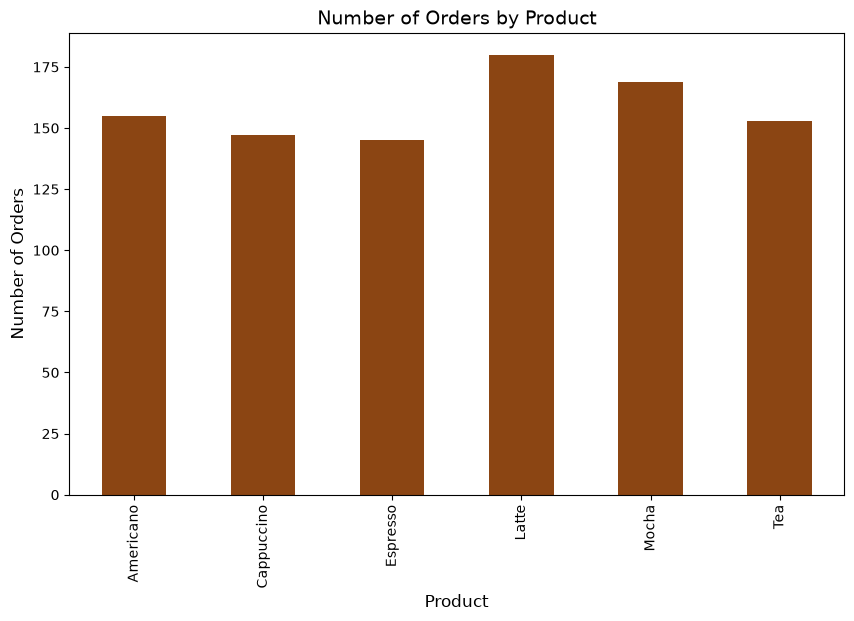

In [11]:
plt.figure(figsize=(10, 6))
product_orders.plot(kind='bar', color='saddlebrown')
plt.title('Number of Orders by Product', fontsize=14)
plt.xlabel('Product', fontsize=12)
plt.ylabel('Number of Orders', fontsize=12)
plt.show()

In [12]:
print(df.groupby('Product')['Quantity'].sum().sort_values(ascending=False))

Product
Latte         512
Mocha         461
Cappuccino    397
Tea           382
Americano     380
Espresso      365
Name: Quantity, dtype: int64


In [13]:
product_analysis = df.groupby("Product").agg(
    Order_Count=("Order_ID", "count"),
    Total_Revenue=("Total", "sum"),
    Average_Order_Amount=("Total", "mean"),
    Median_Order_Amount=("Total", "median")
)
print(product_analysis)

            Order_Count  Total_Revenue  Average_Order_Amount  \
Product                                                        
Americano           155         1547.0              9.980645   
Cappuccino          147         2433.0             16.551020   
Espresso            145         1301.5              8.975862   
Latte               180         2866.5             15.925000   
Mocha               169         3030.5             17.931953   
Tea                 153         1161.0              7.588235   

            Median_Order_Amount  
Product                          
Americano                   8.0  
Cappuccino                 12.0  
Espresso                    7.0  
Latte                      16.5  
Mocha                      13.0  
Tea                         6.0  


In [14]:
product_revenue = df.groupby("Product")["Total"].sum().reset_index()
print(product_revenue)

      Product   Total
0   Americano  1547.0
1  Cappuccino  2433.0
2    Espresso  1301.5
3       Latte  2866.5
4       Mocha  3030.5
5         Tea  1161.0


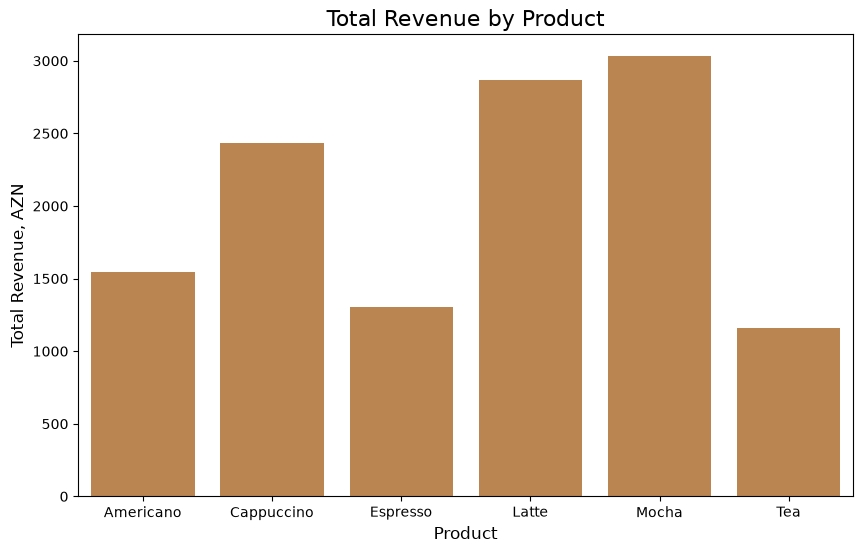

In [56]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=product_revenue,
    x="Product",
    y="Total",
    color="peru"
)
plt.title("Total Revenue by Product", fontsize=16)
plt.xlabel("Product", fontsize=12)
plt.ylabel("Total Revenue, AZN", fontsize=12)
plt.show()

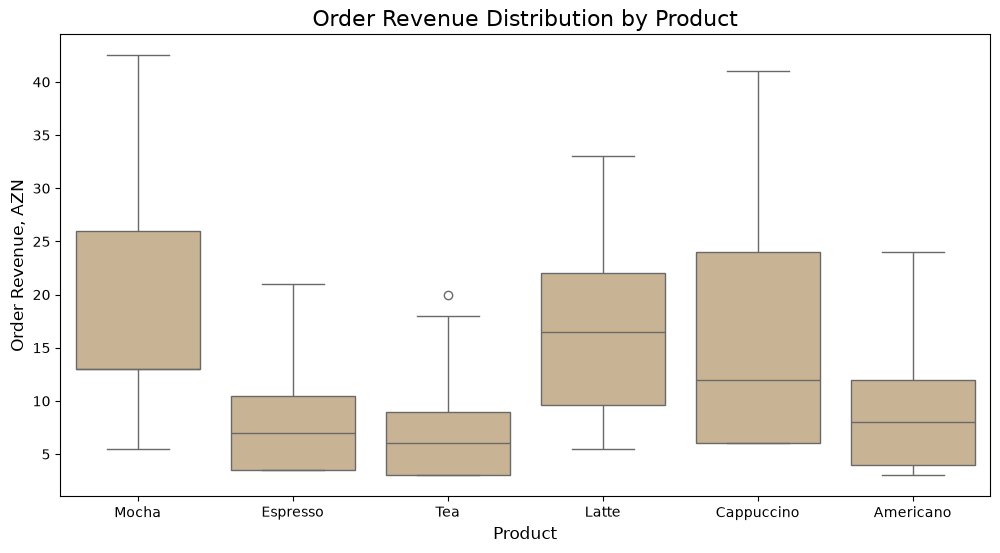

In [57]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df,
    x="Product",
    y="Total",
    color="tan"
)
plt.title("Order Revenue Distribution by Product", fontsize=16)
plt.xlabel("Product", fontsize=12)
plt.ylabel("Order Revenue, AZN", fontsize=12)
plt.show()

**Finding:** Latte leads in quantity sold, while Mocha generates the highest revenue. Product prices and quantities both matter.

## 4. Payment methods

In [17]:
payment_counts = df['Payment_Method'].value_counts()
card_count = payment_counts['Card']
print(card_count)
total_count = df['Payment_Method'].count()
print(total_count)
card_percentage = (card_count / total_count) * 100
print("Card payment percentage:", round(card_percentage, 2), "%")

638
970
Card payment percentage: 65.77 %


C:\Users\HP\AppData\Local\Temp\ipykernel_20828\4091645046.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Payment_Method', palette='Set2')


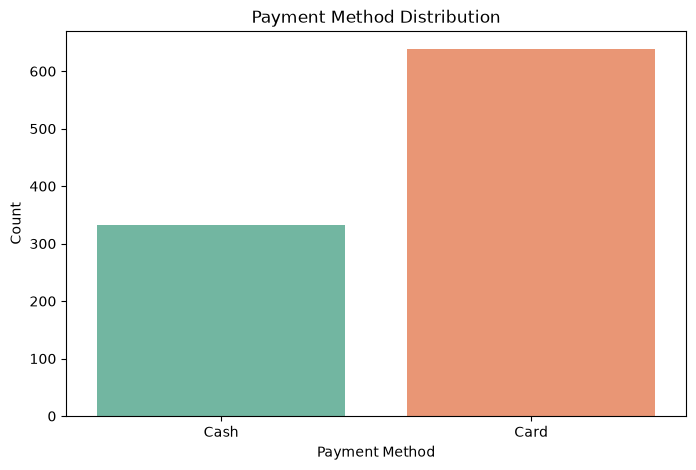

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Payment_Method', palette='Set2')
plt.title('Payment Method Distribution')
plt.xlabel('Payment Method')
plt.ylabel('Count')
plt.show()

In [19]:
payment_analysis = df.groupby("Payment_Method").agg(
    Order_Count=("Order_ID", "count"),
    Total_Revenue=("Total", "sum"),
    Average_Order_Amount=("Total", "mean"),
    Median_Order_Amount=("Total", "median")
)
print(payment_analysis)

                Order_Count  Total_Revenue  Average_Order_Amount  \
Payment_Method                                                     
Card                    638         8109.5             12.710815   
Cash                    332         4448.5             13.399096   

                Median_Order_Amount  
Payment_Method                       
Card                           11.0  
Cash                           11.0  


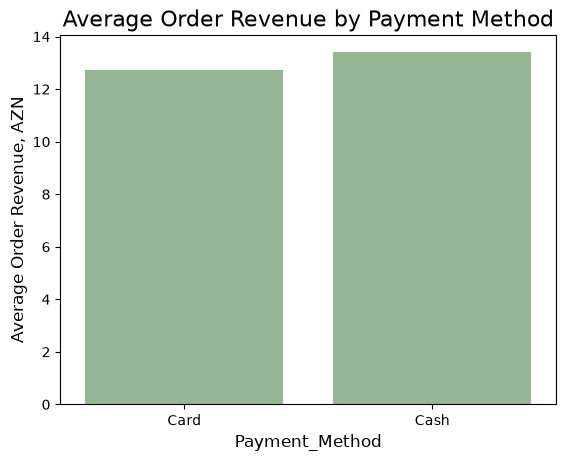

In [58]:
sns.barplot(
    data=payment_analysis.reset_index(),
    x="Payment_Method",
    y="Average_Order_Amount",
    color="darkseagreen"
)
plt.title("Average Order Revenue by Payment Method", fontsize=16)
plt.xlabel("Payment_Method", fontsize=12)
plt.ylabel("Average Order Revenue, AZN", fontsize=12)
plt.show()

**Finding:** Card payments account for 638 of 970 records. Cash payments have a slightly higher average order amount.

## 5. Order size and revenue distribution

In [21]:
order_counts = df['Order_Size'].value_counts().sort_values(ascending=False)
print(order_counts)

Order_Size
Small     543
Medium    292
Large     135
Name: count, dtype: int64


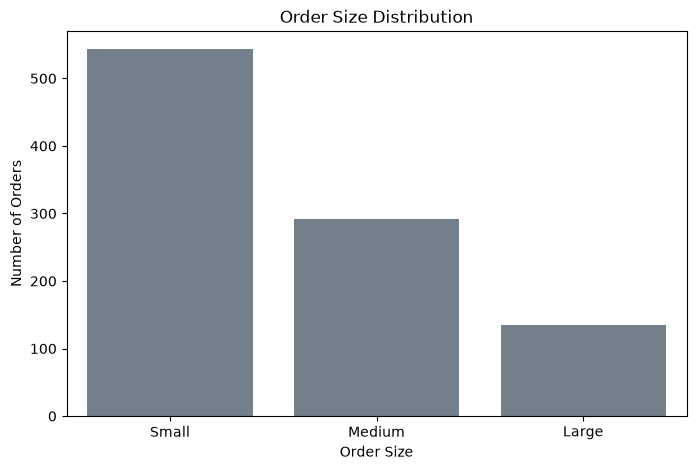

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 5))
sns.countplot( data=df, x='Order_Size', order=['Small', 'Medium', 'Large'],color='slategray')
plt.title('Order Size Distribution')
plt.xlabel('Order Size')
plt.ylabel('Number of Orders')
plt.show()

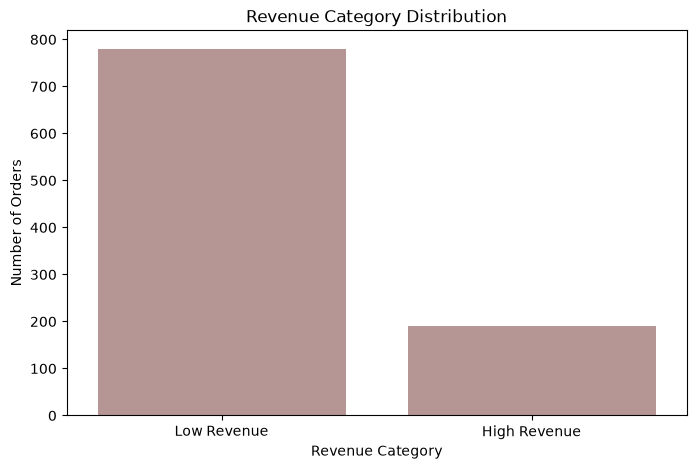

In [60]:
plt.figure(figsize=(8, 5))
sns.countplot( data=df, x='Revenue_Category',color='rosybrown')
plt.title('Revenue Category Distribution')
plt.xlabel('Revenue Category')
plt.ylabel('Number of Orders')
plt.show()

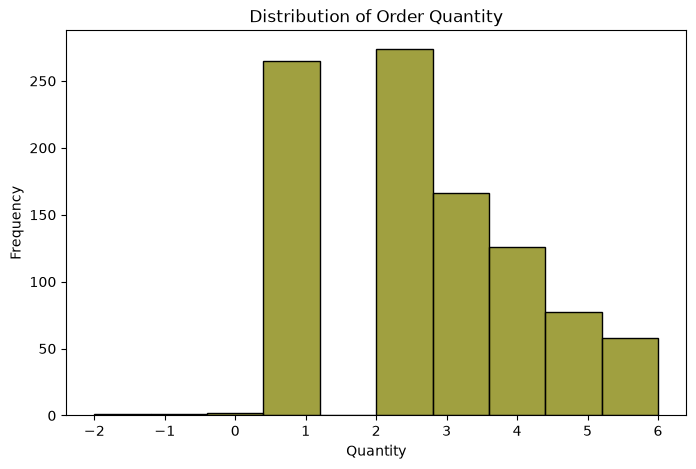

In [61]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Quantity', bins=10, color='olive')
plt.title('Distribution of Order Quantity')
plt.xlabel('Quantity')
plt.ylabel('Frequency')
plt.show()

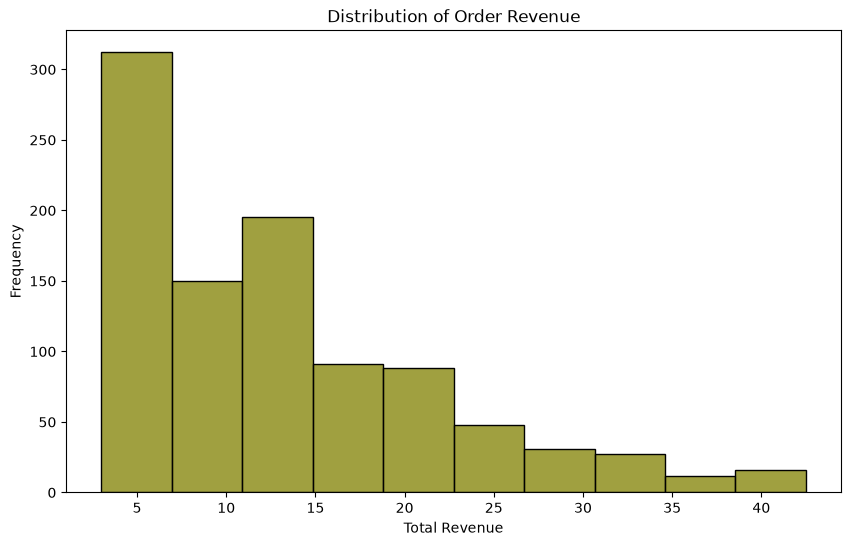

In [62]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='Total', bins=10, color='olive')
plt.title('Distribution of Order Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Frequency')
plt.show()

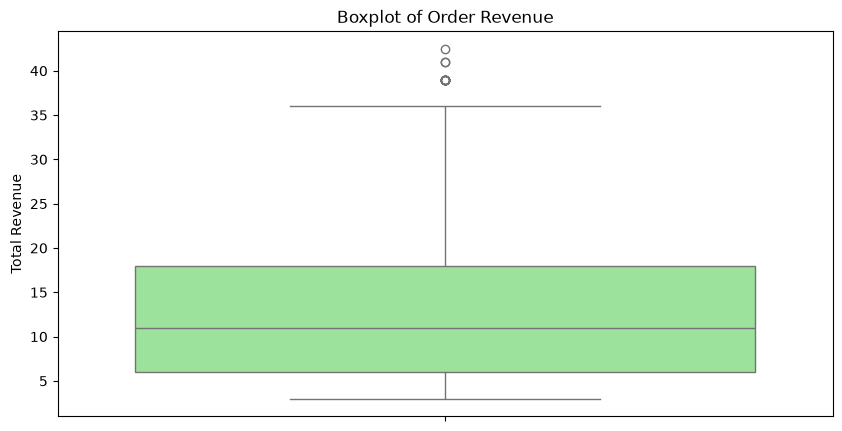

In [26]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, y='Total', color='lightgreen')
plt.title('Boxplot of Order Revenue')
plt.ylabel('Total Revenue')
plt.show()

In [27]:
Q1 = df['Total'].quantile(0.25)
Q3 = df['Total'].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR

high_orders = df[df['Total'] > upper_limit]

print("Upper Limit:", upper_limit)
print(high_orders[[ 'Product', 'Total']])

Upper Limit: 36.0
        Product  Total
59        Mocha   39.0
90   Cappuccino   41.0
113       Mocha   39.0
145       Mocha   39.0
203       Mocha   39.0
261       Mocha   39.0
410       Mocha   42.5
503       Mocha   39.0
532       Mocha   39.0
561       Mocha   39.0
716  Cappuccino   41.0
802       Mocha   39.0
812       Mocha   39.0
839       Mocha   39.0
856       Mocha   39.0
865       Mocha   39.0


## 6. Sales by day

In [28]:
days_order = ['Monday', 'Tuesday', 'Wednesday',
              'Thursday', 'Friday', 'Saturday', 'Sunday']
day_counts = df['Day_Name'].value_counts().reindex(days_order, fill_value=0)
print(day_counts)
print("Day with most orders:", day_counts.idxmax())
print("Day with fewest orders:", day_counts.idxmin())

Day_Name
Monday       122
Tuesday      124
Wednesday    110
Thursday     123
Friday       150
Saturday     111
Sunday       124
Name: count, dtype: int64
Day with most orders: Friday
Day with fewest orders: Wednesday


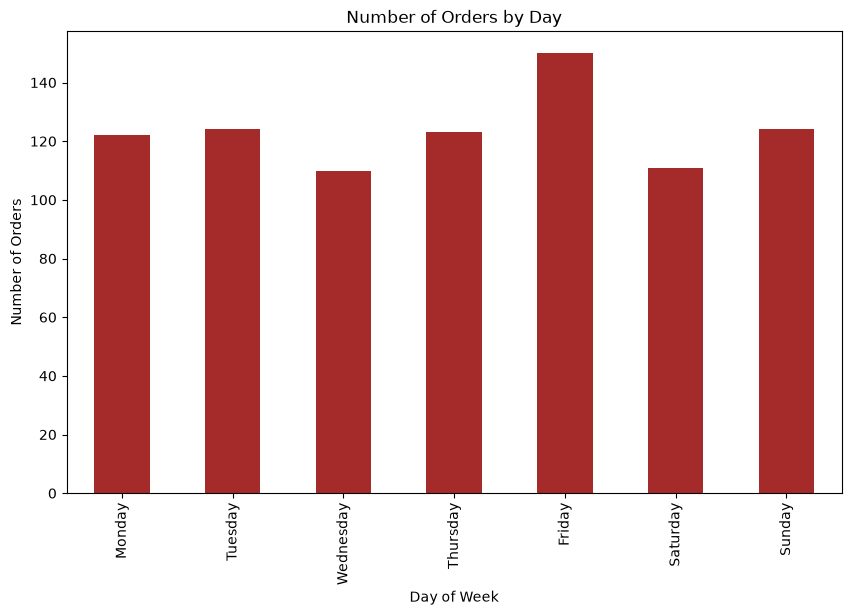

In [29]:
plt.figure(figsize=(10, 6))
day_counts.plot(kind='bar', color='brown')
plt.title('Number of Orders by Day')
plt.xlabel('Day of Week')
plt.ylabel('Number of Orders')
plt.show()

In [30]:
day_analysis = df.groupby("Is_Weekend").agg(
    Order_Count=("Order_ID", "count"),
    Total_Revenue=("Total", "sum"),
    Average_Revenue=("Total", "mean"),
    Median_Revenue=("Total", "median")
)

day_analysis = day_analysis.rename(
    index={False: "Weekday", True: "Weekend"})

print(day_analysis)

            Order_Count  Total_Revenue  Average_Revenue  Median_Revenue
Is_Weekend                                                             
Weekday             735         9540.0        12.979592            11.0
Weekend             235         3018.0        12.842553            11.0


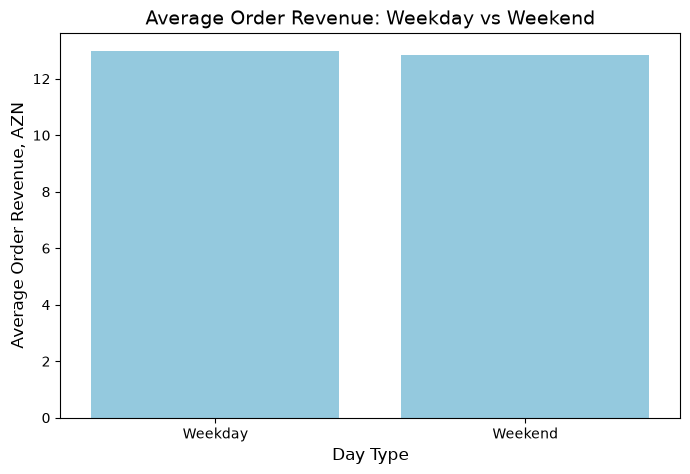

In [31]:
plt.figure(figsize=(8, 5))
sns.barplot(
    data=day_analysis.reset_index(),
    x="Is_Weekend",
    y="Average_Revenue",
    color="skyblue"
)
plt.title("Average Order Revenue: Weekday vs Weekend", fontsize=14)
plt.xlabel("Day Type", fontsize=12)
plt.ylabel("Average Order Revenue, AZN", fontsize=12)
plt.show()

In [32]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekday_analysis = df.groupby("Day_Name").agg(
    Order_Count=("Order_ID", "count"),
    Total_Revenue=("Total", "sum"),
    Average_Order_Amount=("Total", "mean")
)

print(weekday_analysis)

weekday_analysis = weekday_analysis.reindex(day_order)
print(weekday_analysis)

           Order_Count  Total_Revenue  Average_Order_Amount
Day_Name                                                   
Friday             150         1973.0             13.153333
Monday             122         1503.5             12.323770
Saturday           111         1498.0             13.495495
Sunday             124         1520.0             12.258065
Thursday           123         1785.5             14.516260
Tuesday            124         1605.5             12.947581
Wednesday          110         1282.0             11.654545
           Order_Count  Total_Revenue  Average_Order_Amount
Day_Name                                                   
Monday             122         1503.5             12.323770
Tuesday            124         1605.5             12.947581
Wednesday          110         1282.0             11.654545
Thursday           123         1785.5             14.516260
Friday             150         1973.0             13.153333
Saturday           111         1498.0   

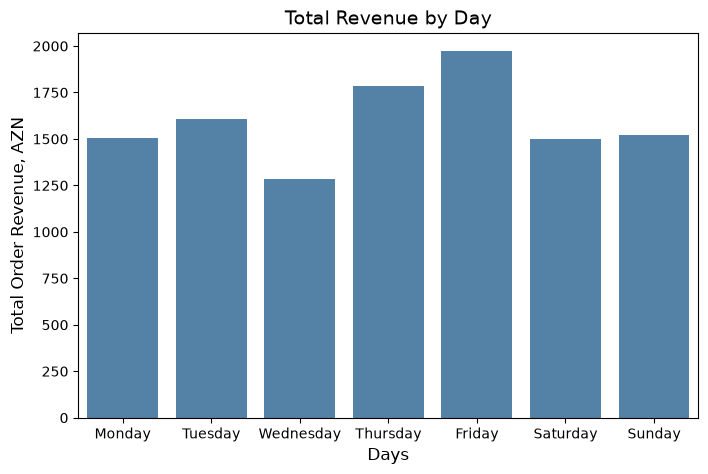

In [63]:
plt.figure(figsize=(8, 5))
sns.barplot(
    data=weekday_analysis.reset_index(),
    x="Day_Name",
    y="Total_Revenue",
    color="steelblue"
)
plt.title("Total Revenue by Day", fontsize=14)
plt.xlabel("Days", fontsize=12)
plt.ylabel("Total Order Revenue, AZN", fontsize=12)
plt.show()

In [34]:
result = df.groupby('Date')['Quantity'].sum()
print("Date with highest sales:", result.idxmax(), result.max())
print("Date with lowest sales:", result.idxmin(), result.min())

Date with highest sales: 2026-01-23 00:00:00 28
Date with lowest sales: 2026-02-24 00:00:00 0


**Finding:** Weekday total revenue is higher, but weekdays and weekends contain different numbers of days. Average order revenue is a separate metric from average daily revenue. Missing dates may affect daily analysis.

## 7. Relationships between variables

In [35]:
quantity_analysis = df.groupby("Quantity").agg(
    Order_Count=("Order_ID", "count"),
    Average_Total=("Total", "mean"),
    Median_Total=("Total", "median"),
    Total_Revenue=("Total", "sum")
)

print(quantity_analysis)

          Order_Count  Average_Total  Median_Total  Total_Revenue
Quantity                                                         
-2                  1       6.000000           6.0            6.0
-1                  1       3.000000           3.0            3.0
 0                  2      15.000000          15.0           30.0
 1                265       4.818868           4.0         1277.0
 2                274       9.830292          11.0         2693.5
 3                166      14.003012          12.0         2324.5
 4                126      19.666667          22.0         2478.0
 5                 77      24.805195          27.5         1910.0
 6                 58      31.655172          33.0         1836.0


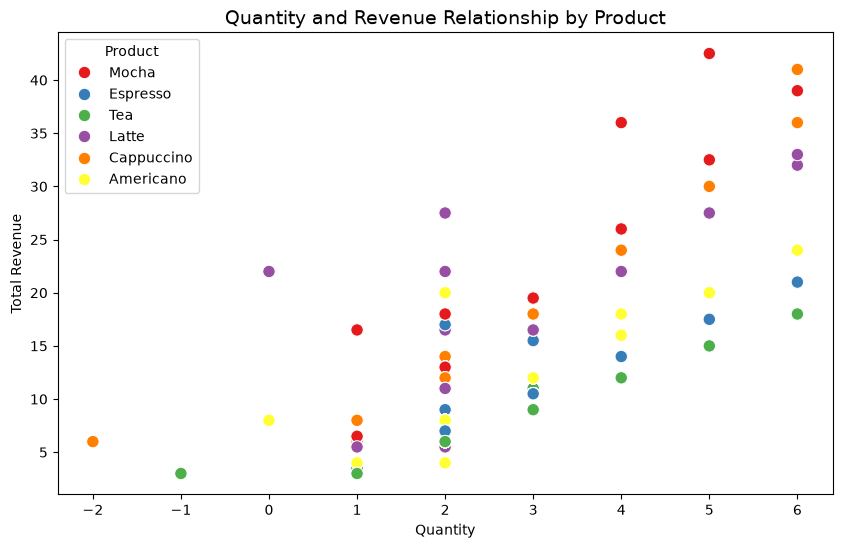

In [36]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Quantity",
    y="Total",
    hue="Product",
    palette="Set1",
    s=80
)

plt.title("Quantity and Revenue Relationship by Product", fontsize=14)
plt.xlabel("Quantity")
plt.ylabel("Total Revenue")
plt.legend(title="Product")
plt.show()

In [37]:
correlation = df["Quantity"].corr(df["Total"])

print("Correlation:", correlation)

print("There is a strong positive relationship")

Correlation: 0.8740934439502829
There is a strong positive relationship


In [38]:
order_size_analysis = df.groupby(
    ["Product", "Order_Size"]
).size().unstack(fill_value=0)

print(order_size_analysis)

Order_Size  Large  Medium  Small
Product                         
Americano      19      42     94
Cappuccino     26      39     82
Espresso       15      46     84
Latte          31      58     91
Mocha          26      52     91
Tea            15      52     86


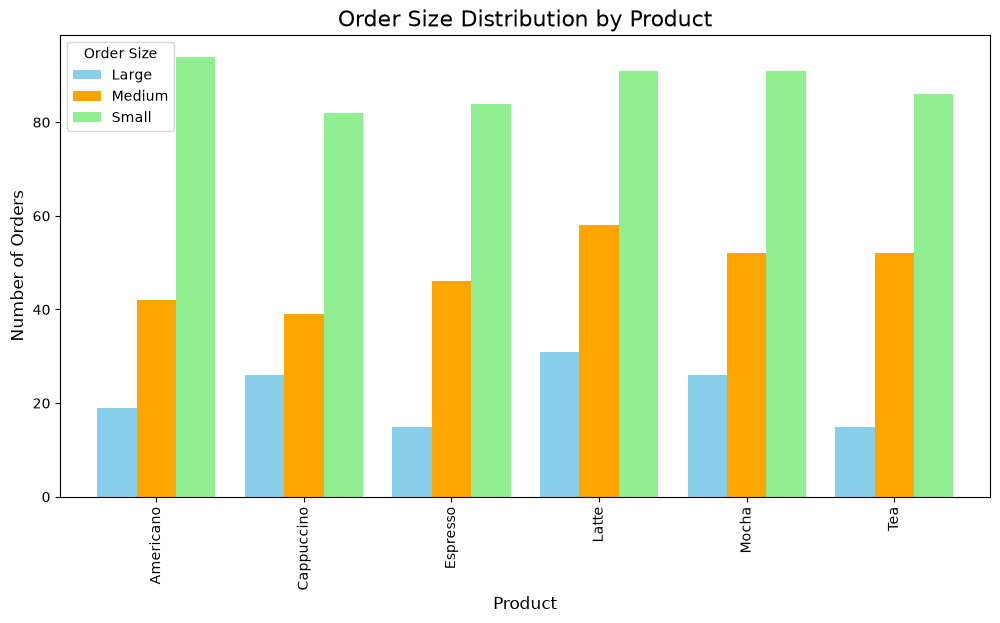

In [39]:
order_size_analysis.plot(
    kind="bar",
    figsize=(12, 6),
    color=["skyblue", "orange", "lightgreen"],
    width=0.8
)
plt.title("Order Size Distribution by Product", fontsize=16)
plt.xlabel("Product", fontsize=12)
plt.ylabel("Number of Orders", fontsize=12)
plt.legend(title="Order Size")
plt.show()

In [40]:
payment_methods_analysis = df.groupby(
    ["Payment_Method", "Revenue_Category"]
).size().unstack(fill_value=0)

print(payment_methods_analysis)

Revenue_Category  High Revenue  Low Revenue
Payment_Method                             
Card                       116          522
Cash                        74          258


In [41]:
payment_methods_percentage = payment_methods_analysis.div(
    payment_methods_analysis.sum(axis=1),
    axis=0
) * 100

print(payment_methods_percentage.round(2))

Revenue_Category  High Revenue  Low Revenue
Payment_Method                             
Card                     18.18        81.82
Cash                     22.29        77.71


**Finding:** Quantity and total revenue have a positive relationship. Different product prices explain why identical quantities can produce different revenue amounts.

## 8. Multivariate analysis

In [42]:
result = df.groupby(
    ["Product", "Is_Weekend"]
).agg(
    Order_Count=("Total", "count"),
    Total_Revenue=("Total", "sum"),
    Average_Order=("Total", "mean"),
    Median_Order=("Total", "median")
).reset_index()

result["Is_Weekend"] = result["Is_Weekend"].map({
    False: "Weekday",
    True: "Weekend"
})

print(result)

       Product Is_Weekend  Order_Count  Total_Revenue  Average_Order  \
0    Americano    Weekday          113         1175.0      10.398230   
1    Americano    Weekend           42          372.0       8.857143   
2   Cappuccino    Weekday          108         1791.0      16.583333   
3   Cappuccino    Weekend           39          642.0      16.461538   
4     Espresso    Weekday          108          950.0       8.796296   
5     Espresso    Weekend           37          351.5       9.500000   
6        Latte    Weekday          139         2195.5      15.794964   
7        Latte    Weekend           41          671.0      16.365854   
8        Mocha    Weekday          127         2313.0      18.212598   
9        Mocha    Weekend           42          717.5      17.083333   
10         Tea    Weekday          122          931.0       7.631148   
11         Tea    Weekend           31          230.0       7.419355   

    Median_Order  
0            8.0  
1            8.0  
2     

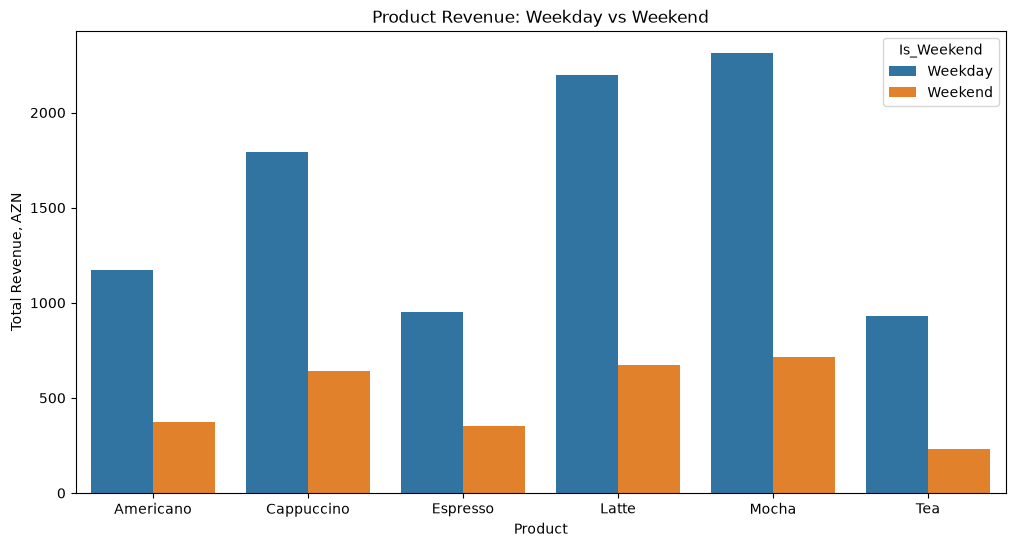

In [43]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=result,
    x="Product",
    y="Total_Revenue",
    hue="Is_Weekend"
)

plt.title("Product Revenue: Weekday vs Weekend")
plt.xlabel("Product")
plt.ylabel("Total Revenue, AZN")
plt.legend(title="Is_Weekend")
plt.show()

In [44]:
payment_result = df.groupby(
    ["Product", "Payment_Method"]
).agg(
    Order_Count=("Total", "count"),
    Total_Revenue=("Total", "sum"),
    Average_Order=("Total", "mean")
).reset_index()

print(payment_result)

       Product Payment_Method  Order_Count  Total_Revenue  Average_Order
0    Americano           Card          106         1051.0       9.915094
1    Americano           Cash           49          496.0      10.122449
2   Cappuccino           Card           95         1518.0      15.978947
3   Cappuccino           Cash           52          915.0      17.596154
4     Espresso           Card          100          927.5       9.275000
5     Espresso           Cash           45          374.0       8.311111
6        Latte           Card          115         1839.0      15.991304
7        Latte           Cash           65         1027.5      15.807692
8        Mocha           Card          108         1883.0      17.435185
9        Mocha           Cash           61         1147.5      18.811475
10         Tea           Card          102          780.0       7.647059
11         Tea           Cash           51          381.0       7.470588


Text(0, 0.5, 'Total Revenue, AZN')

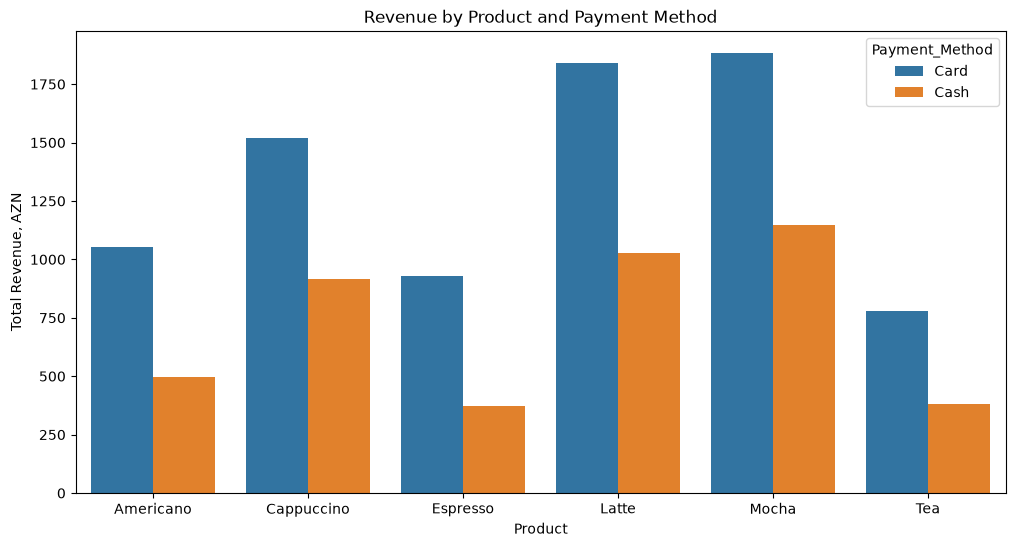

In [45]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=payment_result,
    x="Product",
    y="Total_Revenue",
    hue="Payment_Method"
)

plt.title("Revenue by Product and Payment Method")
plt.xlabel("Product")
plt.ylabel("Total Revenue, AZN")

In [46]:
days_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

daily_revenue = df.pivot_table(
    index="Day_Name",
    columns="Product",
    values="Total",
    aggfunc="sum",
    fill_value=0
)

daily_revenue = daily_revenue.reindex(days_order)

print(daily_revenue)

Product    Americano  Cappuccino  Espresso  Latte  Mocha    Tea
Day_Name                                                       
Monday         200.0       174.0     161.0  392.5  406.5  138.0
Tuesday        226.0       276.0     141.5  516.0  286.0  138.0
Wednesday      143.0       264.0     129.5  198.0  364.0  171.0
Thursday       242.0       490.0     143.5  390.5  357.5  156.0
Friday         304.0       280.0     210.0  462.0  530.0  155.0
Saturday       116.0       258.0     126.0  484.0  338.0  150.0
Sunday         256.0       384.0     225.5  187.0  379.5   80.0


In [47]:
pivot = df.pivot_table(
    index="Day_Name",
    columns="Product",
    values="Total",
    aggfunc="sum",
    fill_value=0
)

pivot = pivot.reindex(days_order)

print(pivot)

Product    Americano  Cappuccino  Espresso  Latte  Mocha    Tea
Day_Name                                                       
Monday         200.0       174.0     161.0  392.5  406.5  138.0
Tuesday        226.0       276.0     141.5  516.0  286.0  138.0
Wednesday      143.0       264.0     129.5  198.0  364.0  171.0
Thursday       242.0       490.0     143.5  390.5  357.5  156.0
Friday         304.0       280.0     210.0  462.0  530.0  155.0
Saturday       116.0       258.0     126.0  484.0  338.0  150.0
Sunday         256.0       384.0     225.5  187.0  379.5   80.0


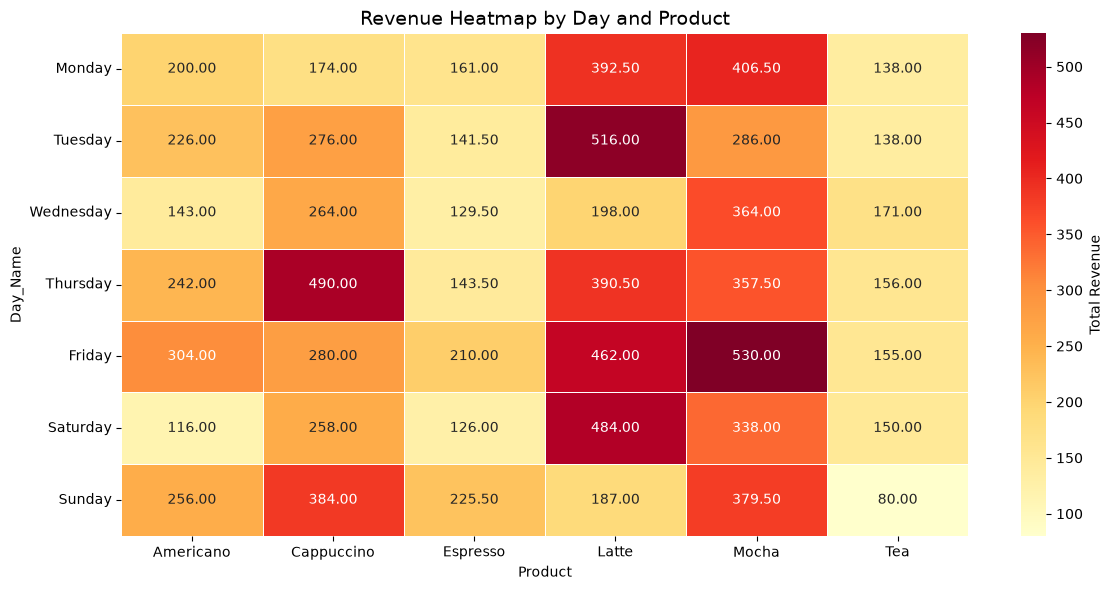

In [48]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    pivot,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Total Revenue"}
)

plt.title("Revenue Heatmap by Day and Product", fontsize=14)
plt.xlabel("Product")
plt.ylabel("Day_Name")

plt.tight_layout()
plt.show()

In [49]:
days_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

pivot = df.pivot_table(
    index="Day_Name",
    columns="Order_Size",
    values="Total",
    aggfunc="sum",
    fill_value=0
)

pivot = pivot.reindex(days_order)
print(pivot)

Order_Size  Large  Medium  Small
Day_Name                        
Monday      365.5   610.0  528.0
Tuesday     417.5   670.0  518.0
Wednesday   301.5   524.0  456.5
Thursday    624.5   715.5  445.5
Friday      531.0   835.5  606.5
Saturday    555.0   508.0  435.0
Sunday      447.5   495.5  577.0


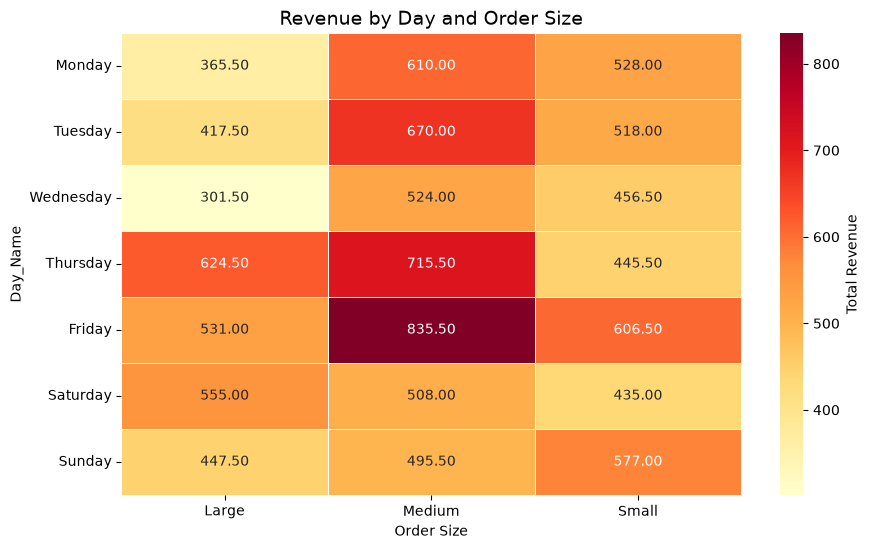

In [50]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    pivot,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Total Revenue"}
)

plt.title("Revenue by Day and Order Size", fontsize=14)
plt.xlabel("Order Size")
plt.ylabel("Day_Name")
plt.show()

**Finding:** Comparing products across days, payment methods and order sizes helps identify opportunities for targeted promotions.

## 9. Order segmentation

In [51]:
segment1 = df[
    (df["Is_Weekend"] == True) &
    (df["Order_Size"] == "Large") &
    (df["Revenue_Category"] == "High Revenue")
]

print("Number of orders:", len(segment1))
print("Total revenue:", segment1["Total"].sum())
print("Most ordered product:", segment1["Product"].mode().iloc[0] if not segment1.empty else "None")
print("Average quantity:", segment1["Quantity"].mean())
print("Average revenue:", segment1["Total"].mean())

Number of orders: 30
Total revenue: 905.0
Most ordered product: Latte
Average quantity: 5.466666666666667
Average revenue: 30.166666666666668


In [52]:
segment2 = df[
    (df["Is_Weekend"] == False) &
    (df["Order_Size"] == "Small") &
    (df["Revenue_Category"] == "Low Revenue")
]

print("Number of orders:", len(segment2))
print("Total revenue:", segment2["Total"].sum())
print("Most ordered product:", segment2["Product"].mode().iloc[0] if not segment2.empty else "None")
print("Average quantity:", segment2["Quantity"].mean())
print("Average revenue:", segment2["Total"].mean())

Number of orders: 400
Total revenue: 2884.0
Most ordered product: Tea
Average quantity: 1.4875
Average revenue: 7.21


In [53]:
segment3 = df[
    (df["Payment_Method"] == "Card") &
    (df["Revenue_Category"] == "High Revenue")
]

print("Number of orders:", len(segment3))
print("Total revenue:", segment3["Total"].sum())
print("Most ordered product:", segment3["Product"].mode().iloc[0] if not segment3.empty else "None")
print("Average quantity:", segment3["Quantity"].mean())
print("Average revenue:", segment3["Total"].mean())

Number of orders: 116
Total revenue: 3194.5
Most ordered product: Latte
Average quantity: 4.827586206896552
Average revenue: 27.538793103448278


In [54]:
segment4 = df[
    (df["Payment_Method"] == "Cash") &
    (df["Order_Size"] == "Large")
]

print("Number of orders:", len(segment4))
print("Total revenue:", segment4["Total"].sum())
print("Most ordered product:", segment4["Product"].mode().iloc[0] if not segment4.empty else "None")
print("Average quantity:", segment4["Quantity"].mean())
print("Average revenue:", segment4["Total"].mean())

Number of orders: 54
Total revenue: 1486.5
Most ordered product: Latte
Average quantity: 5.407407407407407
Average revenue: 27.52777777777778


##  Business recommendations

- Promote lower-selling products through discounts or bundles.
- Maintain convenient card payment options.
- Plan inventory and staffing around observed sales patterns.
- Test targeted promotions by product and day of week.


## Limitations

- Some records contain missing values, which may affect aggregated results.
- The analysis is limited to the available dataset.
- The findings represent historical sales patterns and may not reflect future customer behavior.